In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

In [2]:
DATA_PATH = Path("../data/raw/student_mental_health.csv")
df = pd.read_csv(DATA_PATH)
df = df.drop("Student_ID", axis=1)

In [3]:
display(df.head())

,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,22,Male,3,6.60,17.60,2.91,6.90,7.50,Moderate,8.50,4.00,78.00,No,Poor,No,High
1,21,Male,4,5.60,22.40,2.92,7.60,11.50,Low,4.50,5.30,85.40,Yes,Average,No,Medium
2,22,Male,5,7.10,28.10,2.68,6.50,8.90,Low,4.80,6.10,79.50,No,Average,No,Medium
3,24,Male,1,4.50,14.80,2.23,5.50,7.60,High,3.70,8.00,73.90,No,Average,Yes,High
4,20,Female,1,6.70,17.20,2.69,4.30,7.00,Moderate,8.00,7.40,99.80,Yes,NaN,No,Medium


In [4]:
print("Dataset shape:", df.shape)

print("Number of students:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (2000, 16)
Number of students: 2000
Number of columns: 16


In [5]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


In [6]:
print("\nData types:")
display(df.dtypes)


Data types:


Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [7]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2000 non-null   int64  
 1   Gender                          2000 non-null   str    
 2   Year_of_Study                   2000 non-null   int64  
 3   Sleep_Hours                     1938 non-null   float64
 4   Study_Hours_Per_Week            2000 non-null   float64
 5   GPA                             1962 non-null   float64
 6   Social_Media_Hours              1942 non-null   float64
 7   Screen_Time_Hours               2000 non-null   float64
 8   Physical_Activity               2000 non-null   str    
 9   Financial_Stress                1909 non-null   float64
 10  Family_Support                  1946 non-null   float64
 11  Attendance_Rate                 1953 non-null   float64
 12  Part_Time_Job          

In [8]:
print("\nDataset description:")
display(df.describe(include="all"))


Dataset description:


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000.00,2000,2000.00,1938.00,2000.00,1962.00,1942.00,2000.00,2000,1909.00,1946.00,1953.00,2000,1931,2000,2000
unique,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,2,3,2,3
top,NaN,Female,NaN,NaN,NaN,NaN,NaN,NaN,Moderate,NaN,NaN,NaN,No,Average,No,High
freq,NaN,971,NaN,NaN,NaN,NaN,NaN,NaN,906,NaN,NaN,NaN,1289,860,1408,680
mean,21.13,NaN,2.63,6.76,20.00,2.56,6.01,8.55,NaN,5.96,6.52,85.08,NaN,NaN,NaN,NaN
std,2.14,NaN,1.32,1.13,5.72,0.34,1.15,1.66,NaN,1.89,1.84,7.22,NaN,NaN,NaN,NaN
min,17.00,NaN,1.00,3.30,2.40,1.50,2.10,3.30,NaN,1.40,1.70,54.40,NaN,NaN,NaN,NaN
25%,20.00,NaN,1.00,6.00,16.00,2.32,5.22,7.40,NaN,4.50,5.10,80.30,NaN,NaN,NaN,NaN
50%,21.00,NaN,2.00,6.70,19.80,2.56,6.00,8.50,NaN,6.10,6.70,85.10,NaN,NaN,NaN,NaN
75%,23.00,NaN,4.00,7.60,24.00,2.79,6.70,9.70,NaN,7.40,8.00,90.00,NaN,NaN,NaN,NaN


In [9]:
print("\nDataset null values:")
df.isnull().sum()


Dataset null values:


Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [10]:
numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = df.select_dtypes(exclude=["number"]).columns.tolist()

### Missing values

In [11]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df)
    ) * 100
})
missing_values = missing_values.sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_values[missing_values["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


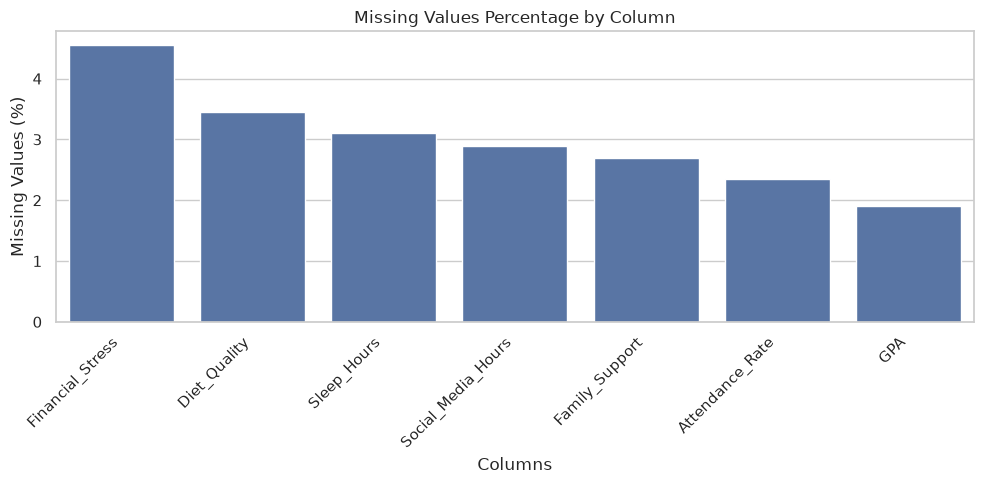

In [12]:
missing = missing_values[missing_values["Missing_Count"] > 0]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing,
    x=missing.index,
    y="Missing_Percentage"
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Duplicates

In [13]:
# Count duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)])
else:
    print("No duplicated rows found.")

Number of duplicated rows: 0
No duplicated rows found.


### inconsistencies

In [14]:
# check categorical inconsistencies
for column in categorical_columns:

    print(df[column].value_counts(dropna=False))
    print("Unique values:", df[column].nunique(), "\n")

Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64
Unique values: 3 

Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64
Unique values: 3 

Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64
Unique values: 2 

Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64
Unique values: 3 

Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64
Unique values: 2 

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64
Unique values: 3 



In [15]:
validations = {
    "Age": (df["Age"] >= 7) & (df["Age"] <= 30),

    "Year_of_Study": df["Year_of_Study"].between(1, 5),

    "Sleep_Hours": df["Sleep_Hours"].between(2, 14),

    "Screen_Time_Hours": df["Screen_Time_Hours"].between(1, 14),

    "GPA": df["GPA"].between(1.5, 4),

    "Attendance_Rate": df["Attendance_Rate"].between(30, 100),

    "Financial_Stress": df["Financial_Stress"].between(1, 10),

    "Family_Support": df["Family_Support"].between(1, 10)
}

for column, condition in validations.items():

    invalid_count = (
        df[column].notna() & ~condition
    ).sum()

    print(f"{column}: {invalid_count} invalid values")

Age: 0 invalid values
Year_of_Study: 0 invalid values
Sleep_Hours: 0 invalid values
Screen_Time_Hours: 0 invalid values
GPA: 0 invalid values
Attendance_Rate: 0 invalid values
Financial_Stress: 0 invalid values
Family_Support: 0 invalid values


In [16]:
logical_checks = {
    "Social media exceeds total screen time": {
        "condition": df["Social_Media_Hours"] <= df["Screen_Time_Hours"],
        "columns": ["Social_Media_Hours", "Screen_Time_Hours"]
    },

    "Sleep + screen time exceeds 24 hours": {
        "condition": (df["Sleep_Hours"] + df["Screen_Time_Hours"]) <= 24,
        "columns": ["Sleep_Hours", "Screen_Time_Hours"]
    },

    "Study hours + weekly sleep exceeds 168 hours": {
        "condition": (df["Study_Hours_Per_Week"] + df["Sleep_Hours"] * 7) <= 168,
        "columns": ["Study_Hours_Per_Week", "Sleep_Hours"]
    }
}

for check_name, check in logical_checks.items():

    condition = check["condition"]
    columns = check["columns"]

    valid_data = df[columns].notna().all(axis=1)
    invalid_count = (valid_data & ~condition).sum()

    print(f"{check_name}: {invalid_count} inconsistent rows")

Social media exceeds total screen time: 37 inconsistent rows
Sleep + screen time exceeds 24 hours: 0 inconsistent rows
Study hours + weekly sleep exceeds 168 hours: 0 inconsistent rows


### Detect outliers using IQR

In [17]:
# Exclude the identifier from numerical analysis
outlier_results = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(df)
        ) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.sort_values(
        by="Outlier_Count",
        ascending=False
    )
)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
5,Social_Media_Hours,3.01,8.91,20,1.00
9,Attendance_Rate,65.75,104.55,12,0.60
4,GPA,1.61,3.50,9,0.45
3,Study_Hours_Per_Week,4.00,36.00,7,0.35
6,Screen_Time_Hours,3.95,13.15,7,0.35
0,Age,15.50,27.50,4,0.20
2,Sleep_Hours,3.60,10.00,2,0.10
1,Year_of_Study,-3.50,8.50,0,0.00
7,Financial_Stress,0.15,11.75,0,0.00
8,Family_Support,0.75,12.35,0,0.00


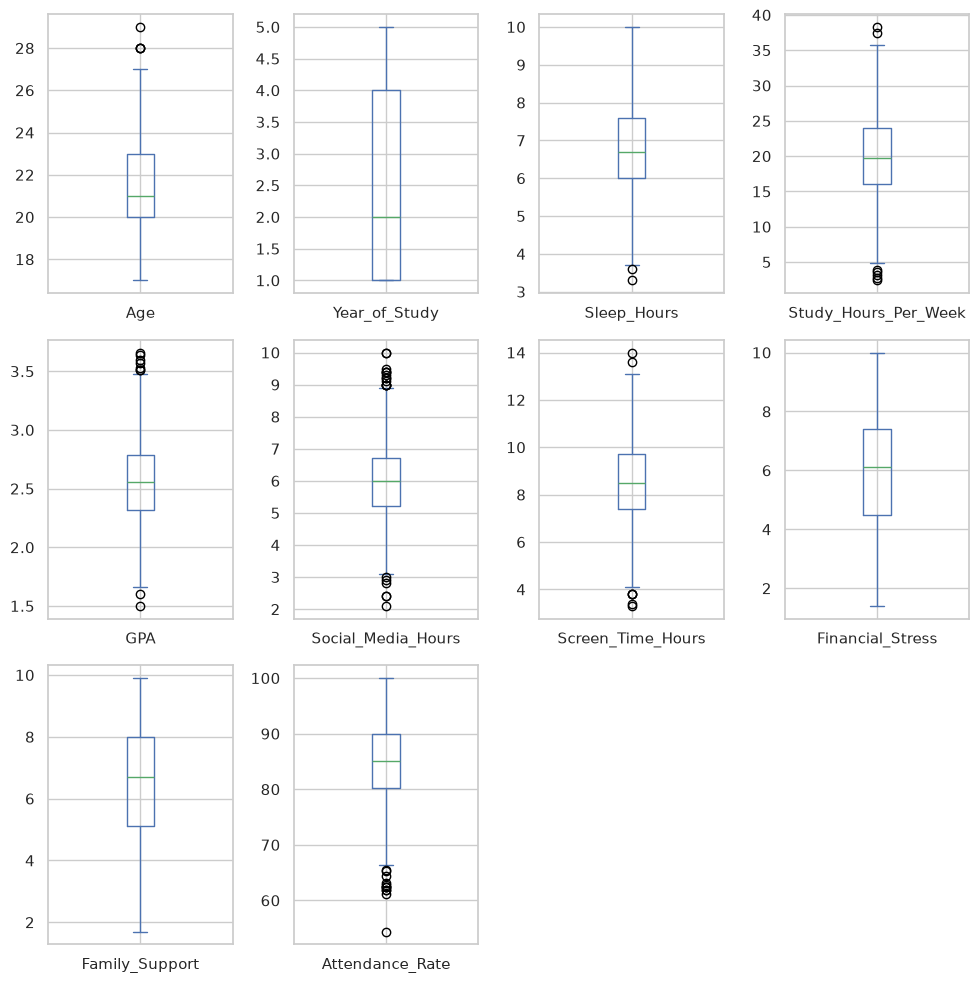

In [18]:
# Visualize outliers

df[numerical_columns].plot(
    kind="box",
    subplots=True,
    layout=(3, 4),
    figsize=(10, 10)
)

plt.tight_layout()
plt.show()

### Descriptive statistics

In [19]:
# Numerical statistics
numerical_stats = df[numerical_columns].describe().T

display(numerical_stats)

,count,mean,std,min,25%,50%,75%,max
Age,2000.00,21.13,2.14,17.00,20.00,21.00,23.00,29.00
Year_of_Study,2000.00,2.63,1.32,1.00,1.00,2.00,4.00,5.00
Sleep_Hours,1938.00,6.76,1.13,3.30,6.00,6.70,7.60,10.00
Study_Hours_Per_Week,2000.00,20.00,5.72,2.40,16.00,19.80,24.00,38.30
GPA,1962.00,2.56,0.34,1.50,2.32,2.56,2.79,3.66
Social_Media_Hours,1942.00,6.01,1.15,2.10,5.22,6.00,6.70,10.00
Screen_Time_Hours,2000.00,8.55,1.66,3.30,7.40,8.50,9.70,14.00
Financial_Stress,1909.00,5.96,1.89,1.40,4.50,6.10,7.40,10.00
Family_Support,1946.00,6.52,1.84,1.70,5.10,6.70,8.00,9.90
Attendance_Rate,1953.00,85.08,7.22,54.40,80.30,85.10,90.00,100.00


In [20]:
# Categorical statistics
categorical_stats = df[categorical_columns].describe().T

display(categorical_stats)

,count,unique,top,freq
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408
Mental_Health_Risk,2000,3,High,680


### Target variable analysis

In [21]:
# Distribution of the target
target_counts = df["Mental_Health_Risk"].value_counts()
target_percentages = df["Mental_Health_Risk"].value_counts(normalize=True) * 100

target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_distribution)

,Count,Percentage
Mental_Health_Risk,,
High,680,34.00
Medium,660,33.00
Low,660,33.00


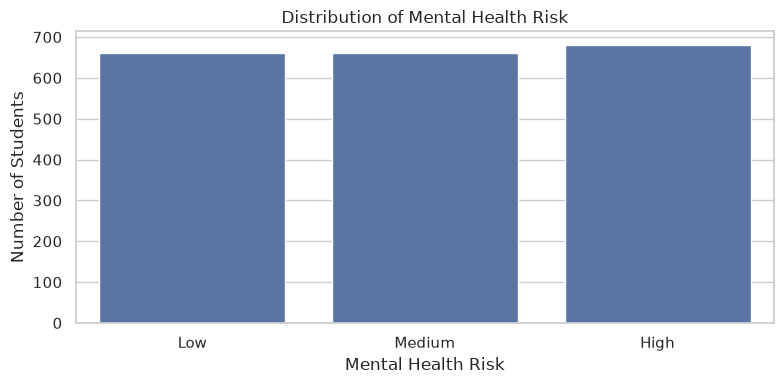

In [22]:
# Visualize target distribution
plt.figure(figsize=(8, 4))

sns.countplot(
    data=df,
    x="Mental_Health_Risk",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Mental Health Risk")
plt.xlabel("Mental Health Risk")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

7. Univariate analysis

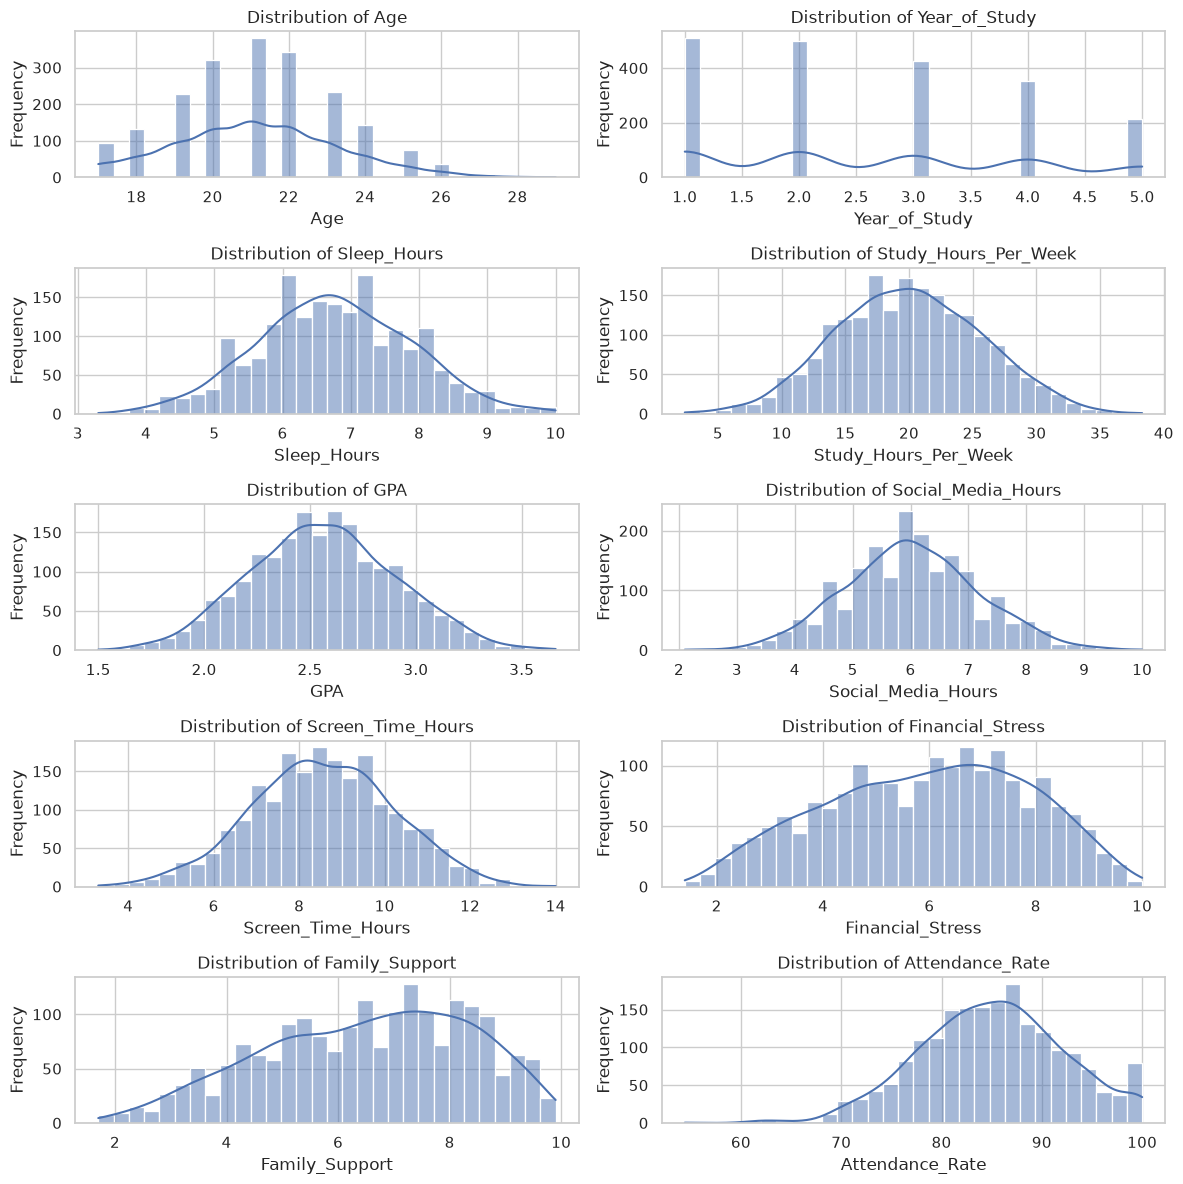

In [23]:
# Numerical feature distributions

fig, axes = plt.subplots(5, 2, figsize=(12, 12))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

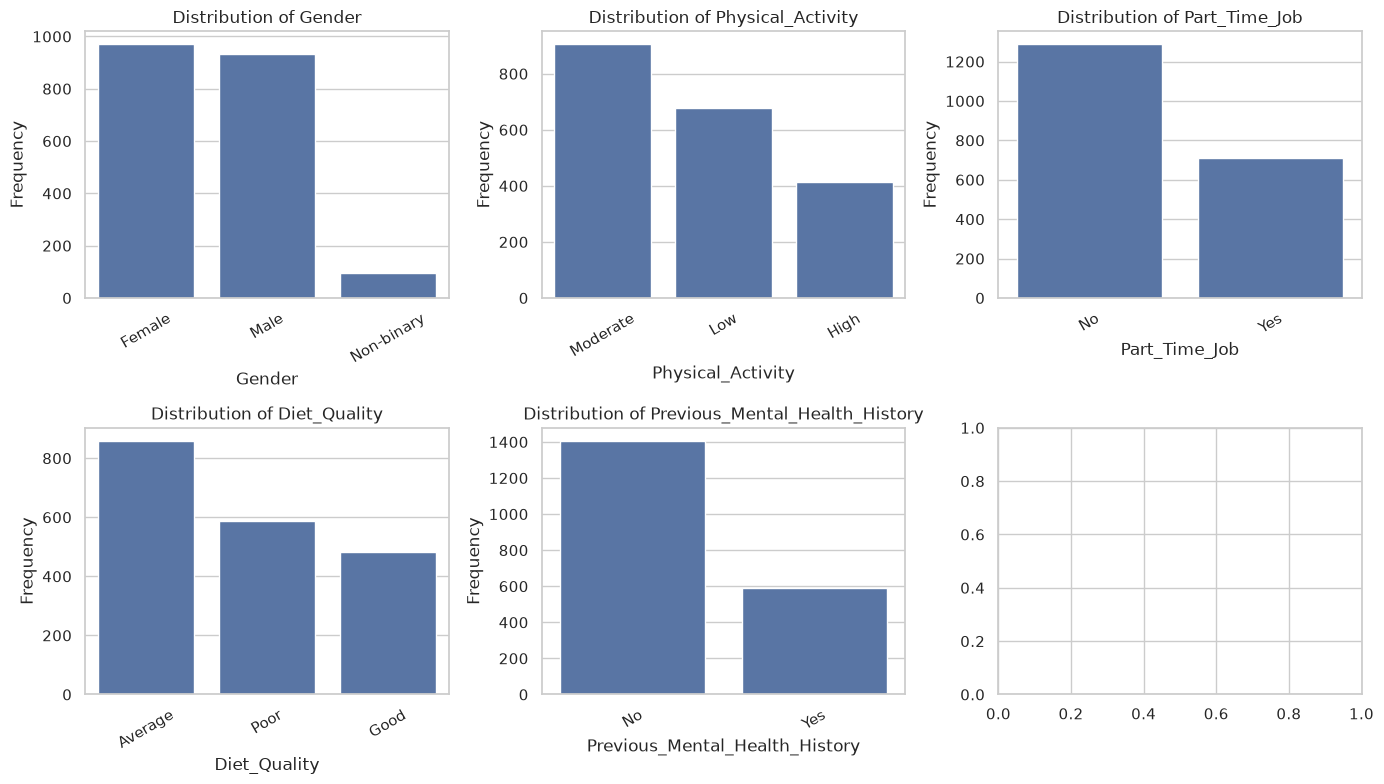

In [24]:
# Categorical feature distributions

columns = [col for col in categorical_columns
           if col not in ["Student_ID", "Mental_Health_Risk"]]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, column in enumerate(columns):

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

8. Bivariate analysis

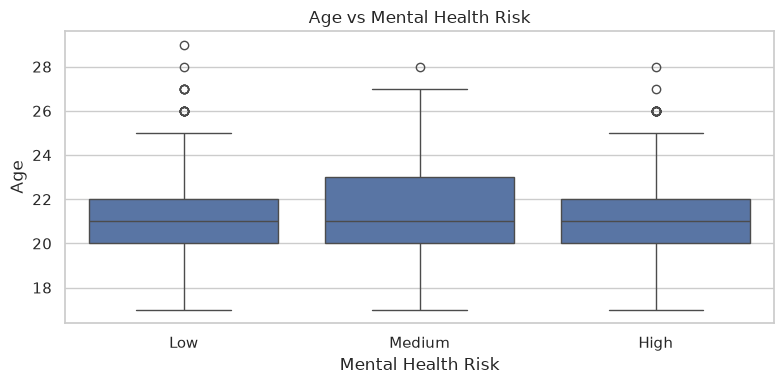

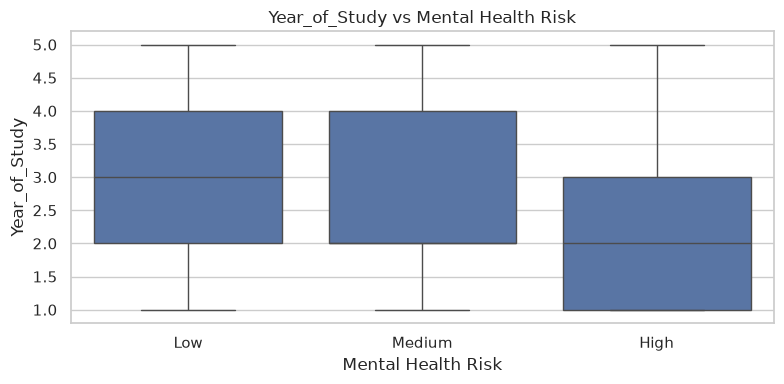

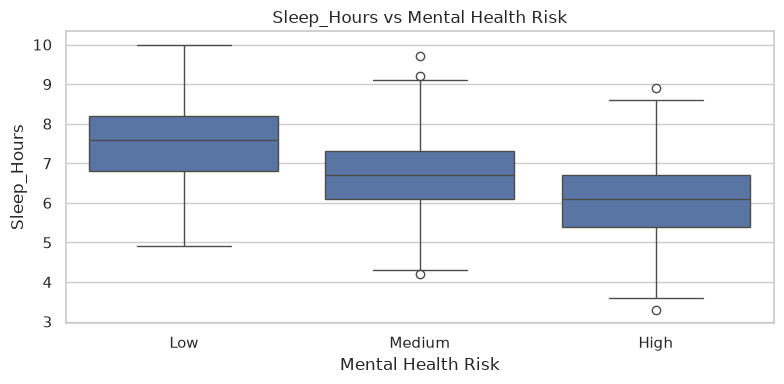

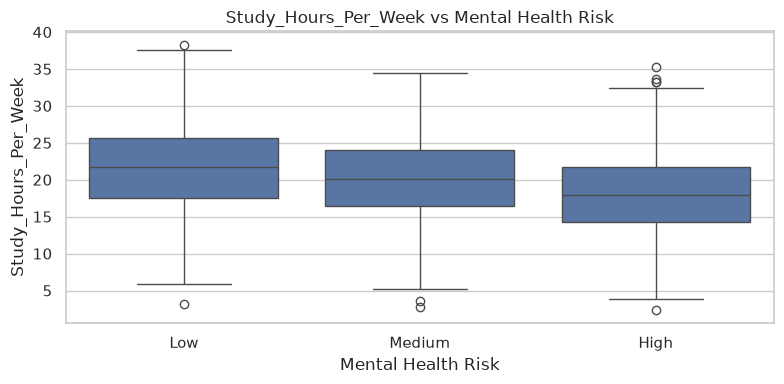

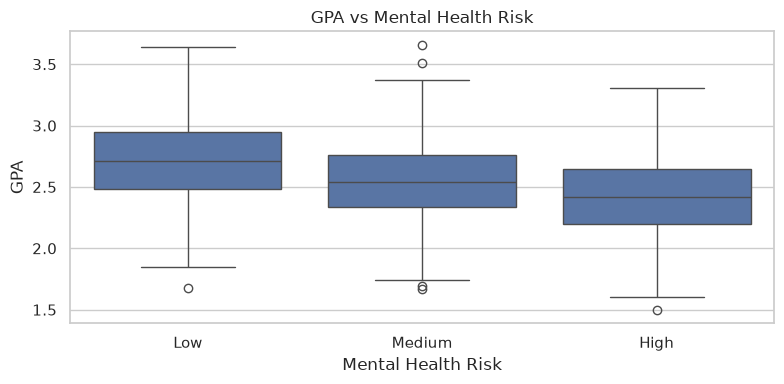

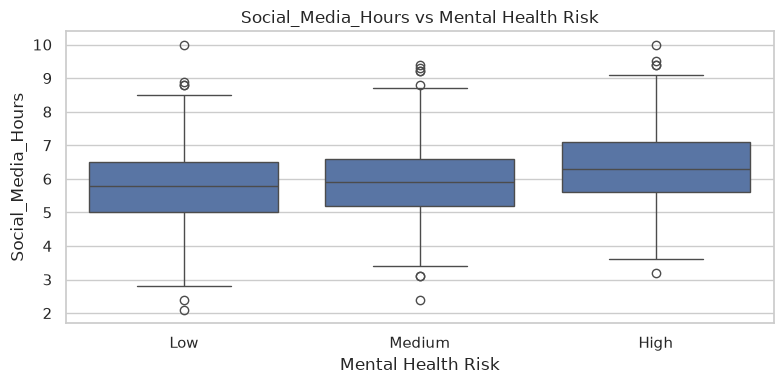

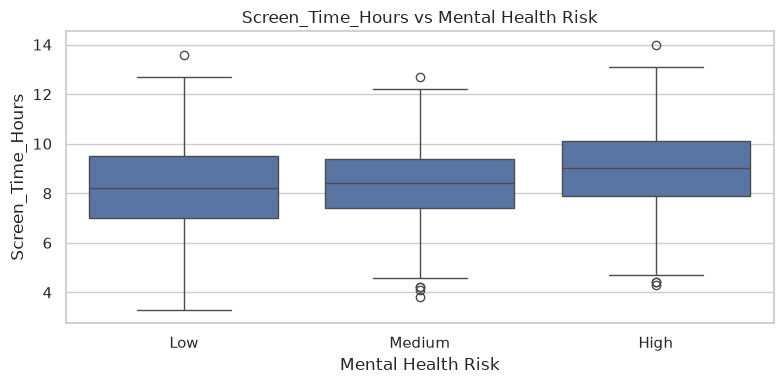

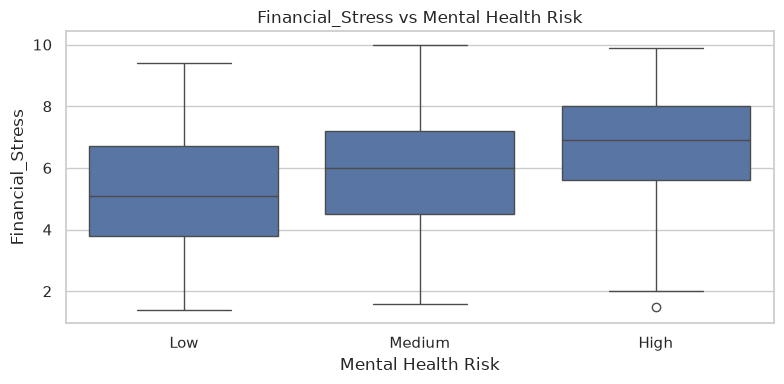

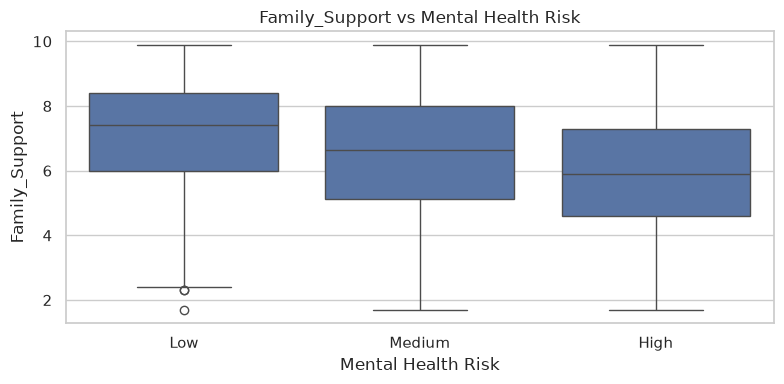

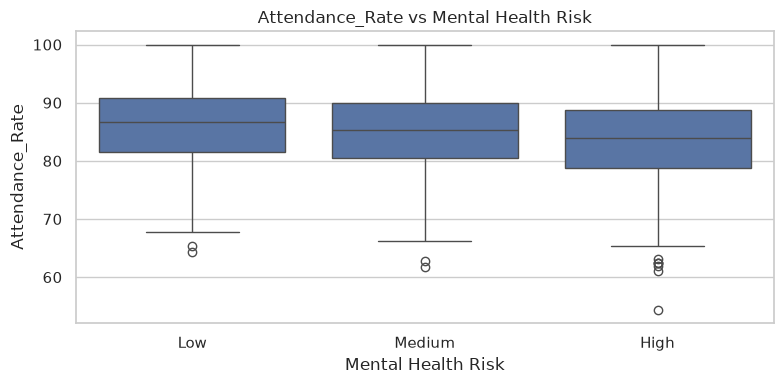

In [25]:
# Numerical features versus target
numerical_features = numerical_columns.copy()

for column in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="Mental_Health_Risk",
        y=column,
        order=["Low", "Medium", "High"]
    )

    plt.title(f"{column} vs Mental Health Risk")
    plt.xlabel("Mental Health Risk")
    plt.ylabel(column)

    plt.tight_layout()
    plt.show()


Gender vs Mental_Health_Risk


Mental_Health_Risk,High,Low,Medium
Gender,,,
Female,336,325,310
Male,311,296,325
Non-binary,33,39,25


Mental_Health_Risk,High,Low,Medium
Gender,,,
Female,34.60,33.47,31.93
Male,33.37,31.76,34.87
Non-binary,34.02,40.21,25.77


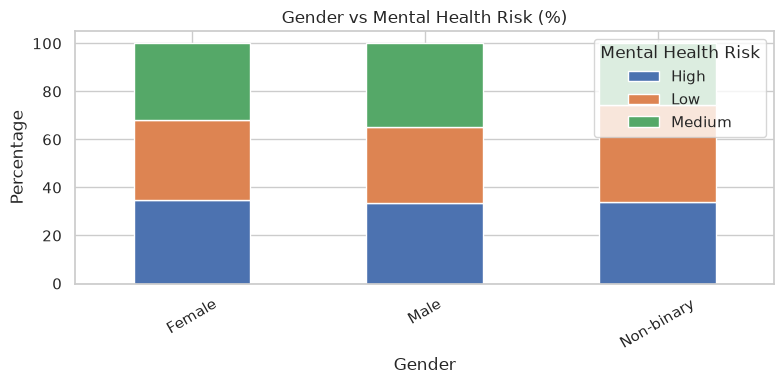


Physical_Activity vs Mental_Health_Risk


Mental_Health_Risk,High,Low,Medium
Physical_Activity,,,
High,84,205,126
Low,312,155,212
Moderate,284,300,322


Mental_Health_Risk,High,Low,Medium
Physical_Activity,,,
High,20.24,49.40,30.36
Low,45.95,22.83,31.22
Moderate,31.35,33.11,35.54


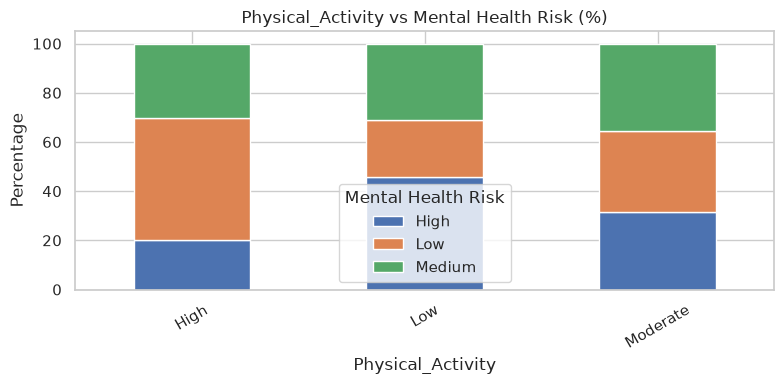


Part_Time_Job vs Mental_Health_Risk


Mental_Health_Risk,High,Low,Medium
Part_Time_Job,,,
No,390,467,432
Yes,290,193,228


Mental_Health_Risk,High,Low,Medium
Part_Time_Job,,,
No,30.26,36.23,33.51
Yes,40.79,27.14,32.07


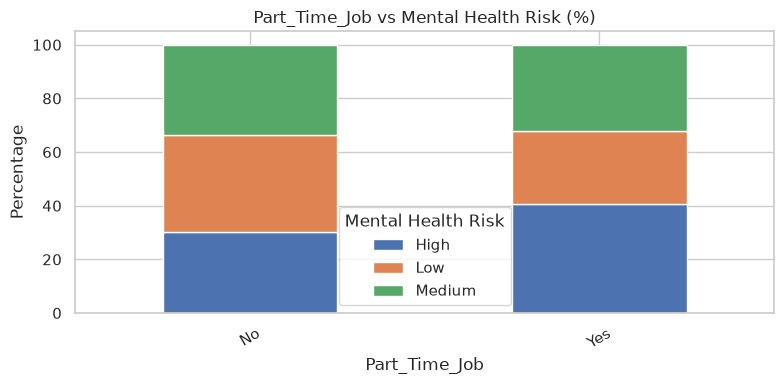


Diet_Quality vs Mental_Health_Risk


Mental_Health_Risk,High,Low,Medium
Diet_Quality,,,
Average,278,288,294
Good,133,207,144
Poor,248,141,198


Mental_Health_Risk,High,Low,Medium
Diet_Quality,,,
Average,32.33,33.49,34.19
Good,27.48,42.77,29.75
Poor,42.25,24.02,33.73


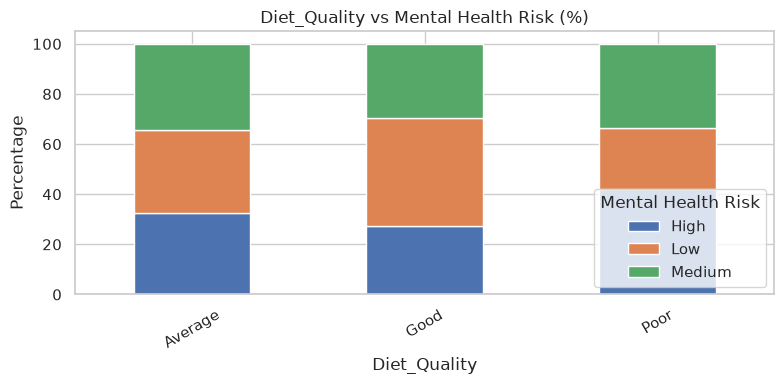


Previous_Mental_Health_History vs Mental_Health_Risk


Mental_Health_Risk,High,Low,Medium
Previous_Mental_Health_History,,,
No,386,553,469
Yes,294,107,191


Mental_Health_Risk,High,Low,Medium
Previous_Mental_Health_History,,,
No,27.41,39.28,33.31
Yes,49.66,18.07,32.26


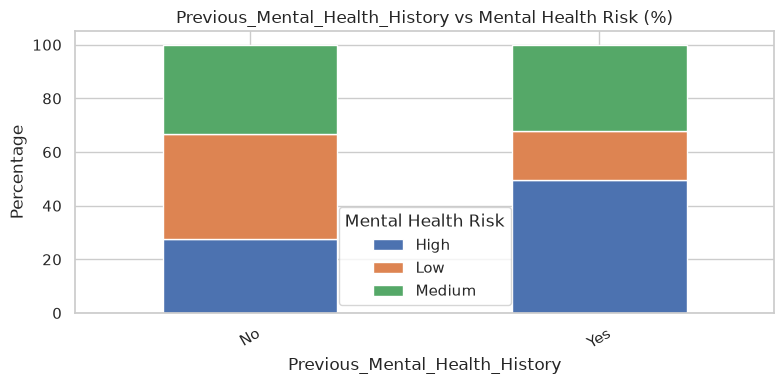

In [26]:
# Categorical features versus target
categorical_features = [
    col for col in categorical_columns
    if col not in ["Student_ID", "Mental_Health_Risk"]
]

for column in categorical_features:

    contingency_table = pd.crosstab(
        df[column],
        df["Mental_Health_Risk"]
    )

    print(f"\n{column} vs Mental_Health_Risk")
    display(contingency_table)

    # Row percentages
    percentage_table = pd.crosstab(
        df[column],
        df["Mental_Health_Risk"],
        normalize="index"
    ) * 100

    display(percentage_table.round(2))

    # Visualization
    percentage_table.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )

    plt.title(f"{column} vs Mental Health Risk (%)")
    plt.xlabel(column)
    plt.ylabel("Percentage")
    plt.legend(title="Mental Health Risk")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

9. Correlation analysis

In [27]:
# Correlation matrix
correlation_matrix = df[
    numerical_columns
].corr(method="pearson")

display(correlation_matrix)

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
Age,1.00,0.00,-0.01,-0.01,0.00,-0.01,-0.01,0.00,-0.01,-0.01
Year_of_Study,0.00,1.00,0.03,0.70,0.34,-0.35,-0.24,-0.01,0.01,0.08
Sleep_Hours,-0.01,0.03,1.00,0.03,0.25,0.00,0.02,0.02,0.01,0.08
Study_Hours_Per_Week,-0.01,0.70,0.03,1.00,0.49,-0.50,-0.33,-0.03,0.04,0.14
GPA,0.00,0.34,0.25,0.49,1.00,-0.23,-0.16,0.00,0.01,0.29
Social_Media_Hours,-0.01,-0.35,0.00,-0.50,-0.23,1.00,0.68,-0.01,-0.06,-0.07
Screen_Time_Hours,-0.01,-0.24,0.02,-0.33,-0.16,0.68,1.00,-0.00,-0.04,-0.06
Financial_Stress,0.00,-0.01,0.02,-0.03,0.00,-0.01,-0.00,1.00,0.05,-0.00
Family_Support,-0.01,0.01,0.01,0.04,0.01,-0.06,-0.04,0.05,1.00,0.00
Attendance_Rate,-0.01,0.08,0.08,0.14,0.29,-0.07,-0.06,-0.00,0.00,1.00


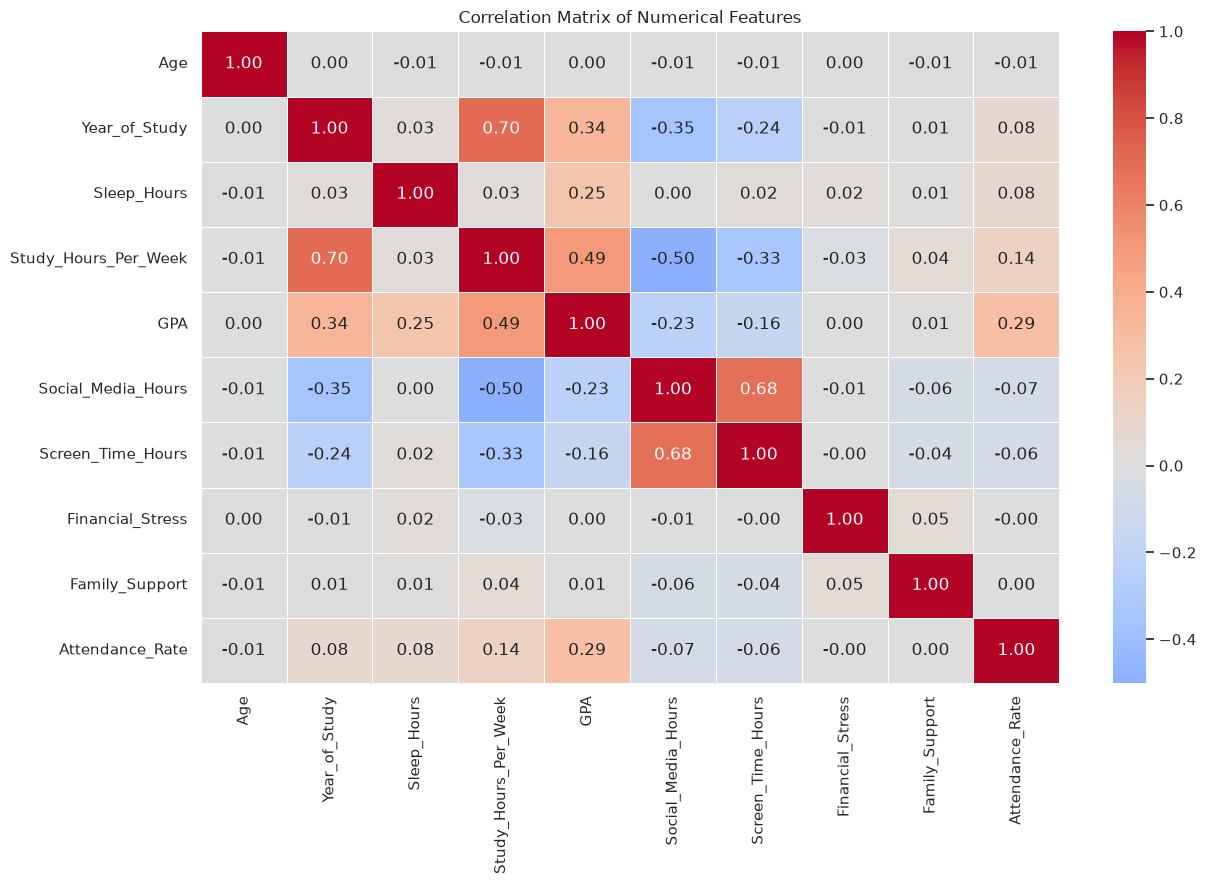

In [28]:
# Correlation heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

Sleep hours, GPA, financial stress and family support show notable associations with the target. These relationships are exploratory and do not imply causation.

In [29]:
# Numerical features and target association
risk_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

risk_encoded = df["Mental_Health_Risk"].map(risk_mapping)

risk_correlations = pd.concat(
    [
        df[numerical_columns],
        risk_encoded.rename("Risk_Encoded")
    ],
    axis=1
).corr(method="spearman")["Risk_Encoded"].drop(
    "Risk_Encoded"
)

display(
    risk_correlations.sort_values(
        ascending=False
    ).to_frame("Spearman_Correlation_With_Risk")
)

,Spearman_Correlation_With_Risk
Financial_Stress,0.31
Social_Media_Hours,0.20
Screen_Time_Hours,0.17
Age,0.01
Attendance_Rate,-0.14
Year_of_Study,-0.17
Study_Hours_Per_Week,-0.24
Family_Support,-0.25
GPA,-0.34
Sleep_Hours,-0.54
